In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

transactions = pd.read_csv(r"D:\Customer Segmentation Analysis\data\processed\transactions_cleaned.csv")

transactions["OrderDate"] = pd.to_datetime(
    transactions["OrderDate"]
)

print("Transactions loaded successfully!")

Transactions loaded successfully!


In [3]:
# RFM values

# setting reference date
reference_date = transactions["OrderDate"].max() + pd.Timedelta(days = 1)

# calculate RFM
rfm = transactions.groupby("CustomerID").agg(
    Recency = ("OrderDate", lambda x: (reference_date - x.max()).days),
    Frequency = ("TransactionID", "nunique"),
    Monetary = ("Sales", "sum")
).reset_index()
print(rfm.head(10))

  CustomerID  Recency  Frequency  Monetary
0     C00001      468          4   1708.39
1     C00002      601          5   1121.89
2     C00003       76          2    761.39
3     C00004       80          5   1362.58
4     C00005      325          3   1472.60
5     C00006       60          1     61.45
6     C00007       19          6   2086.28
7     C00008       58          7   2550.72
8     C00009     1008          2    399.96
9     C00010      260         11   4116.41


In [5]:
print(rfm[["Recency", "Frequency", "Monetary"]].describe())

           Recency    Frequency     Monetary
count  6232.000000  6232.000000  6232.000000
mean    310.104140     5.215019  1503.603809
std     303.939159     3.377968  1079.517870
min       1.000000     1.000000    15.360000
25%      82.000000     3.000000   675.675000
50%     211.500000     5.000000  1264.355000
75%     443.000000     7.000000  2117.747500
max    1752.000000    21.000000  7193.040000


In [6]:
# Assigning RFM scores
# Score 5 = best
# Score 4 = good
# Score 3 = average
# Score 2 = below average
# Score 1 = lowest

# Recency score (lower recency = higher score)
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method = "first"),
    5,
    labels = [5,4,3,2,1]
).astype(int)

# Frequency score (higher frequency = higher score)
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method = "first"),
    5,
    labels = [1,2,3,4,5]
).astype(int)

# Monetary score (higher spending = higher score)
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

print(rfm.head(10))

  CustomerID  Recency  Frequency  Monetary  R_Score  F_Score  M_Score
0     C00001      468          4   1708.39        2        2        4
1     C00002      601          5   1121.89        1        3        3
2     C00003       76          2    761.39        4        1        2
3     C00004       80          5   1362.58        4        3        3
4     C00005      325          3   1472.60        2        2        3
5     C00006       60          1     61.45        5        1        1
6     C00007       19          6   2086.28        5        4        4
7     C00008       58          7   2550.72        5        4        5
8     C00009     1008          2    399.96        1        1        1
9     C00010      260         11   4116.41        3        5        5


In [7]:
# Calculating combined RFM score

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) + 
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

print(rfm.head(10))

  CustomerID  Recency  Frequency  Monetary  R_Score  F_Score  M_Score  \
0     C00001      468          4   1708.39        2        2        4   
1     C00002      601          5   1121.89        1        3        3   
2     C00003       76          2    761.39        4        1        2   
3     C00004       80          5   1362.58        4        3        3   
4     C00005      325          3   1472.60        2        2        3   
5     C00006       60          1     61.45        5        1        1   
6     C00007       19          6   2086.28        5        4        4   
7     C00008       58          7   2550.72        5        4        5   
8     C00009     1008          2    399.96        1        1        1   
9     C00010      260         11   4116.41        3        5        5   

  RFM_Score  
0       224  
1       133  
2       412  
3       433  
4       223  
5       511  
6       544  
7       545  
8       111  
9       355  


In [8]:
# Checking score distribution

print("Recency Score Distribution: ")
print(rfm["R_Score"].value_counts().sort_index())

print("\nFrequency Score Distribution: ")
print(rfm["F_Score"].value_counts().sort_index())

print("\nMonetary Score Distribution: ")
print(rfm["M_Score"].value_counts().sort_index())

Recency Score Distribution: 
R_Score
1    1247
2    1246
3    1246
4    1246
5    1247
Name: count, dtype: int64

Frequency Score Distribution: 
F_Score
1    1247
2    1246
3    1246
4    1246
5    1247
Name: count, dtype: int64

Monetary Score Distribution: 
M_Score
1    1247
2    1246
3    1246
4    1246
5    1247
Name: count, dtype: int64


In [9]:
# creating customer segments

def customer_segment(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champions"

    elif row["F_Score"] >= 4 and row["M_Score"] >= 3:
        return "Loyal Customers"

    elif row["R_Score"] >= 4 and row["F_Score"] <= 2:
        return "Recent Customers"

    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"

    elif row["R_Score"] <= 2 and row["F_Score"] <= 2:
        return "Hibernating"

    else:
        return "Potential Loyalists"

rfm["Customer_Segment"] = rfm.apply(customer_segment, axis = 1)

print(rfm[["CustomerID", "RFM_Score", "Customer_Segment"]].head(10))

  CustomerID RFM_Score     Customer_Segment
0     C00001       224          Hibernating
1     C00002       133              At Risk
2     C00003       412     Recent Customers
3     C00004       433  Potential Loyalists
4     C00005       223          Hibernating
5     C00006       511     Recent Customers
6     C00007       544            Champions
7     C00008       545            Champions
8     C00009       111          Hibernating
9     C00010       355      Loyal Customers


In [10]:
# checking how many customers belong to each segment

print(rfm["Customer_Segment"].value_counts())

Customer_Segment
Hibernating            1440
Champions              1224
Loyal Customers        1202
Potential Loyalists    1200
Recent Customers        634
At Risk                 532
Name: count, dtype: int64


In [21]:
rfm.to_csv(
    r"D:\Customer Segmentation Analysis\data\processed\customer_rfm_segments.csv",
    index=False
)
print("RFM customer segmentation saved.")

RFM customer segmentation saved.


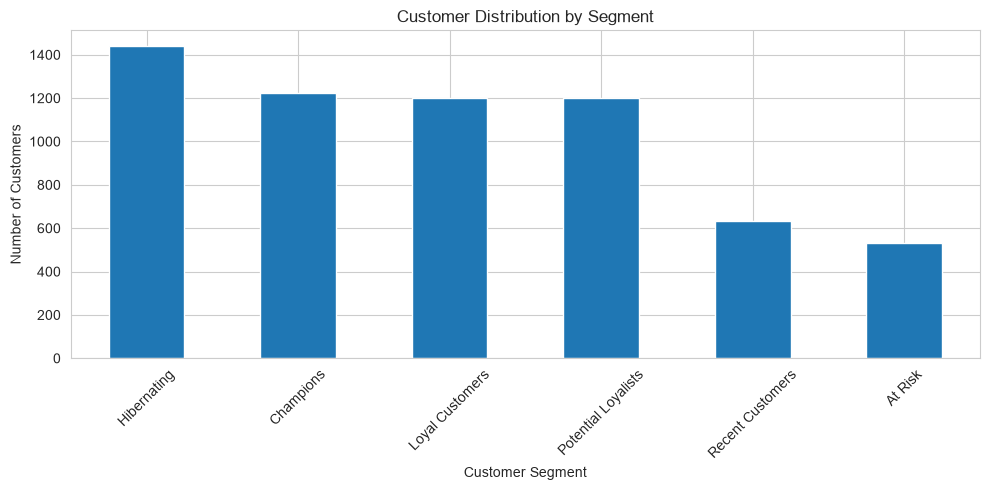

In [12]:
# customer segmentation distribution bar chart and saving
 
# count customers in each segment
segment_counts = rfm["Customer_Segment"].value_counts()

# bar chart
plt.figure(figsize = (10, 5))

segment_counts.plot(kind = "bar")

plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation = 45)
plt.tight_layout()
plt.savefig(
    r"D:\Customer Segmentation Analysis\outputs\figures\customer_segment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [13]:
# calculate segment percentages

segment_percentage = (
    rfm["Customer_Segment"].value_counts(normalize = True) * 100
)

print(segment_percentage.round(2))

Customer_Segment
Hibernating            23.11
Champions              19.64
Loyal Customers        19.29
Potential Loyalists    19.26
Recent Customers       10.17
At Risk                 8.54
Name: proportion, dtype: float64
